# VYUHA — Phase 2: Exploratory Data Analysis (EDA)
**AI-Powered Cybersecurity for Small Industries**

This notebook performs systematic exploratory data analysis on the preprocessed CICIDS2017 dataset (`dev_sample.parquet`, `train.parquet`, and `test.parquet`).

### Objectives
1. Understand baseline network traffic behavior across normal and adversarial flows.
2. Characterize class distributions, extreme imbalance, and rare attack families.
3. Analyze transport and application protocol signatures across destination ports.
4. Investigate traffic dynamics: duration, volume, rates, packet lengths, and TCP flag profiles.
5. Identify multicollinearity and candidate features for intrusion detection modeling.


In [1]:
import json
from pathlib import Path
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Non-blocking headless display
plt.show = lambda *args, **kwargs: None

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['figure.figsize'] = (10, 5)

PROCESSED_DIR = Path("../../datasets/processed")
if not PROCESSED_DIR.exists():
    PROCESSED_DIR = Path("../datasets/processed")
    if not PROCESSED_DIR.exists():
        PROCESSED_DIR = Path("datasets/processed")

print("Using processed data path:", PROCESSED_DIR.resolve())


Using processed data path: /Users/varshasri/VYUHA/datasets/processed


## 1. Dataset Overview & Partition Consistency
We examine the dimensions, features, null counts, and partition alignments between `train.parquet`, `test.parquet`, and `dev_sample.parquet`.


In [2]:
with open(PROCESSED_DIR / "preprocessing_metadata.json") as f:
    meta = json.load(f)

print(f"Total Raw Rows Processed:   {meta['total_raw_rows']:,}")
print(f"Dropped Duplicate Rows:     {meta['dropped_duplicates']:,} ({meta['dropped_duplicates']/meta['total_raw_rows']*100:.2f}%)")
print(f"Deduplicated Population:    {meta['deduplicated_rows']:,}")
print(f"Training Partition (80%):   {meta['train_rows']:,}")
print(f"Testing Partition (20%):    {meta['test_rows']:,}")
print(f"Development Sample:         {meta['dev_sample_rows']:,}")
print(f"Flow Features (X):          {meta['feature_count']}")
print(f"Target Labels (y):          {meta['target_names']}")


Total Raw Rows Processed:   2,830,628
Dropped Duplicate Rows:     331,215 (11.70%)
Deduplicated Population:    2,499,413
Training Partition (80%):   1,999,530
Testing Partition (20%):    499,883
Development Sample:         200,000
Flow Features (X):          77
Target Labels (y):          ['label_raw', 'label_binary', 'label_category']


In [3]:
# Load Dev Sample for in-depth analysis
df_dev = pd.read_parquet(PROCESSED_DIR / "dev_sample.parquet")
print("Dev sample shape:", df_dev.shape)
print("Missing values in dev sample:", df_dev.isna().sum().sum())
print("Infinite values in dev sample:", np.isinf(df_dev.select_dtypes(include=[np.number])).sum().sum())


Dev sample shape: (200000, 80)
Missing values in dev sample: 0
Infinite values in dev sample: 0


## 2. Class Distribution & Imbalance
Analyze binary distribution (Benign vs Attack) and evaluate the long-tail distribution across the 7 attack categories.


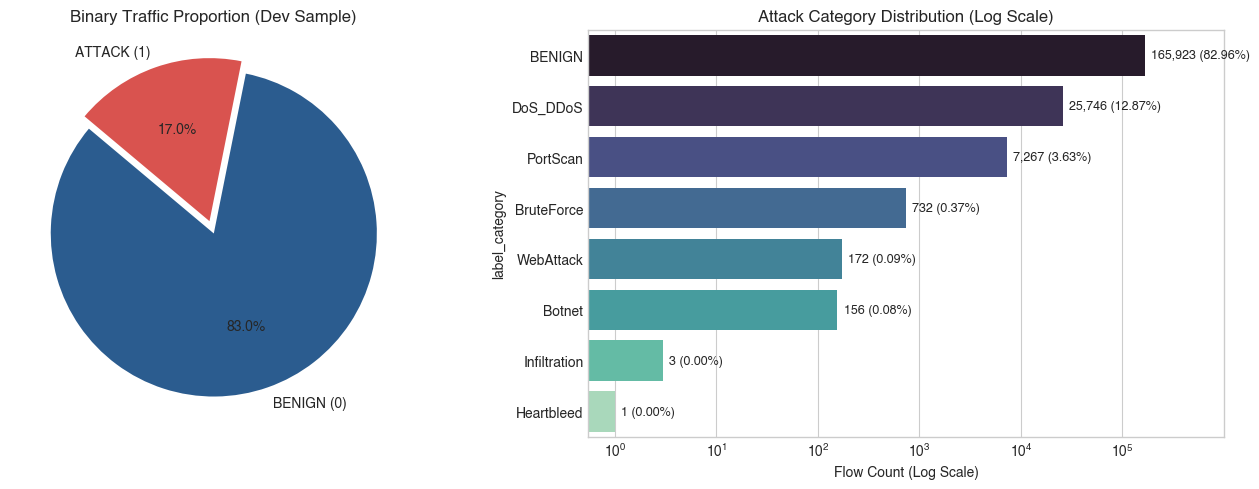

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Binary split
bin_counts = df_dev['label_binary'].value_counts()
ax1.pie(bin_counts, labels=['BENIGN (0)', 'ATTACK (1)'], autopct='%1.1f%%',
        colors=['#2b5c8f', '#d9534f'], startangle=140, explode=(0, 0.08),
        textprops=dict(fontweight='bold'))
ax1.set_title("Binary Traffic Proportion (Dev Sample)", fontsize=12, fontweight='bold')

# Category counts (Log Scale)
cat_counts = df_dev['label_category'].value_counts()
sns.barplot(x=cat_counts.values, y=cat_counts.index, palette="mako", ax=ax2)
ax2.set_xscale("log")
ax2.set_title("Attack Category Distribution (Log Scale)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Flow Count (Log Scale)")
for i, v in enumerate(cat_counts.values):
    ax2.text(v * 1.15, i, f"{v:,} ({v/len(df_dev)*100:.2f}%)", va='center', fontsize=9, fontweight='semibold')
ax2.set_xlim(right=cat_counts.max() * 6)

plt.tight_layout()


## 3. Protocol & Service Port Grouping (Inferred Transport Analysis)
> **Note on Transport Classification**: The CICIDS2017 MachineLearningCVE dataset does not contain an explicit numeric `Protocol` column. Transport-layer analysis is an **inferred classification based on heuristic indicators** (TCP control flags and initial receive window sentinels) and must not be presented as definitive protocol identification.
- **Inferred TCP**: Flows with `Init_Win_bytes_forward != -1` or active flags (`SYN`, `ACK`).
- **Inferred UDP / Stateless**: Flows with sentinel `-1` and 0 TCP control flags.


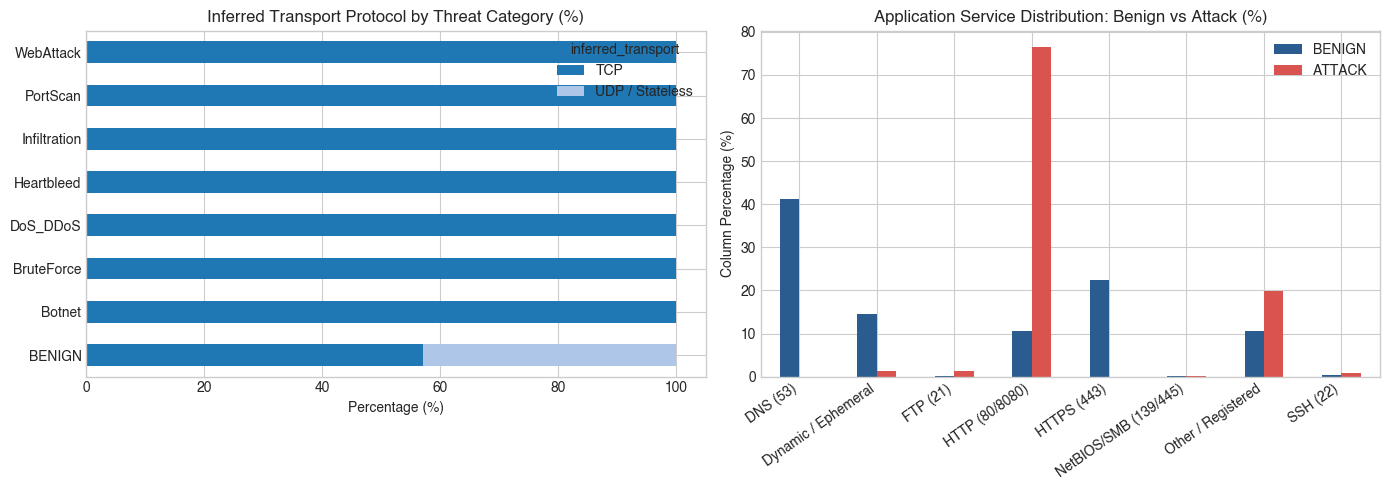

In [5]:
# Inferred Transport Protocol
df_dev['inferred_transport'] = np.where(
    (df_dev['Init_Win_bytes_forward'] != -1) | (df_dev['SYN Flag Count'] > 0) | (df_dev['ACK Flag Count'] > 0),
    'TCP', 'UDP / Stateless'
)

# Application Service Mapping
def map_service(port):
    port = int(port)
    if port in [80, 8080]: return "HTTP (80/8080)"
    if port == 443: return "HTTPS (443)"
    if port == 53: return "DNS (53)"
    if port == 21: return "FTP (21)"
    if port == 22: return "SSH (22)"
    if port in [139, 445]: return "NetBIOS/SMB (139/445)"
    if port >= 49152: return "Dynamic / Ephemeral"
    return "Other / Registered"

df_dev['service_group'] = df_dev['Destination Port'].apply(map_service)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
trans_counts = pd.crosstab(df_dev['label_category'], df_dev['inferred_transport'], normalize='index') * 100
trans_counts.plot(kind='barh', stacked=True, color=['#1f77b4', '#aec7e8'], ax=ax1)
ax1.set_title("Inferred Transport Protocol by Threat Category (%)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Percentage (%)")
ax1.set_ylabel("")

svc_cross = pd.crosstab(df_dev['service_group'], df_dev['label_binary'], normalize='columns') * 100
svc_cross.columns = ['BENIGN', 'ATTACK']
svc_cross.plot(kind='bar', color=['#2b5c8f', '#d9534f'], ax=ax2)
ax2.set_title("Application Service Distribution: Benign vs Attack (%)", fontsize=12, fontweight='bold')
ax2.set_ylabel("Column Percentage (%)")
ax2.set_xlabel("")
plt.xticks(rotation=35, ha='right')

plt.tight_layout()


## 4. Destination Port Targeting Patterns
Identify which ports are disproportionately targeted by malicious flows.


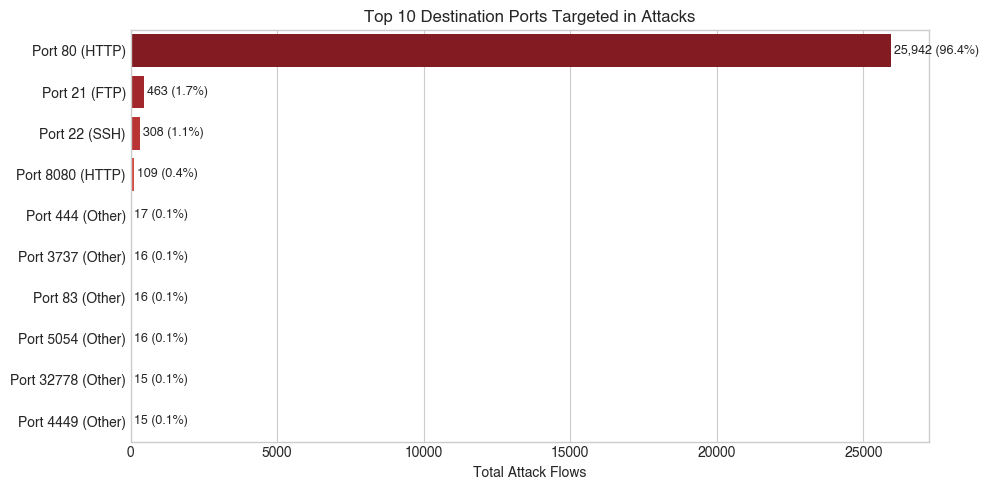

In [6]:
top_attack_ports = df_dev[df_dev['label_binary'] == 1]['Destination Port'].astype(int).value_counts().head(10)
port_labels = [f"Port {p} ({map_service(p).split(' ')[0]})" for p in top_attack_ports.index]

plt.figure(figsize=(10, 5))
sns.barplot(x=top_attack_ports.values, y=port_labels, palette="Reds_r")
plt.title("Top 10 Destination Ports Targeted in Attacks", fontsize=12, fontweight='bold')
plt.xlabel("Total Attack Flows")
for i, v in enumerate(top_attack_ports.values):
    plt.text(v + 100, i, f"{v:,} ({v/top_attack_ports.sum()*100:.1f}%)", va='center', fontsize=9, fontweight='semibold')
plt.tight_layout()


## 5. Traffic Dynamics: Rates, Duration, Packet Sizes & Flags
Analyze flow durations, transfer rates, packet size asymmetries, and TCP control flag distributions.


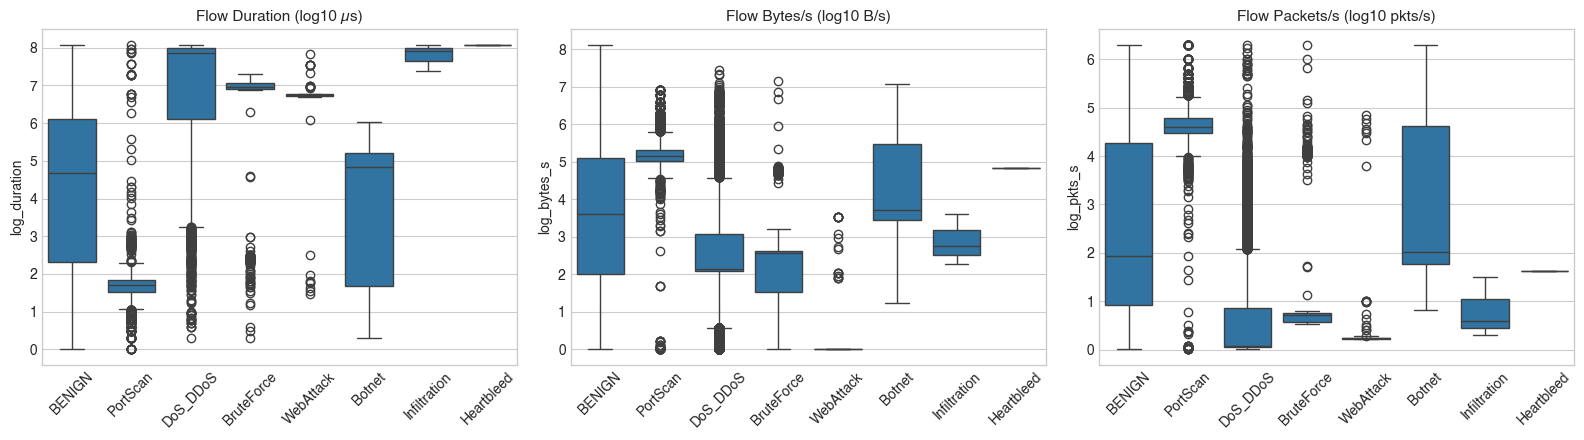

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

df_dev['log_duration'] = np.log10(df_dev['Flow Duration'] + 1)
sns.boxplot(x='label_category', y='log_duration', data=df_dev, ax=axes[0])
axes[0].set_title("Flow Duration (log10 µs)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("")
axes[0].tick_params(axis='x', rotation=45)

df_dev['log_bytes_s'] = np.log10(df_dev['Flow Bytes/s'] + 1)
sns.boxplot(x='label_category', y='log_bytes_s', data=df_dev, ax=axes[1])
axes[1].set_title("Flow Bytes/s (log10 B/s)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("")
axes[1].tick_params(axis='x', rotation=45)

df_dev['log_pkts_s'] = np.log10(df_dev['Flow Packets/s'] + 1)
sns.boxplot(x='label_category', y='log_pkts_s', data=df_dev, ax=axes[2])
axes[2].set_title("Flow Packets/s (log10 pkts/s)", fontsize=11, fontweight='bold')
axes[2].set_xlabel("")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()


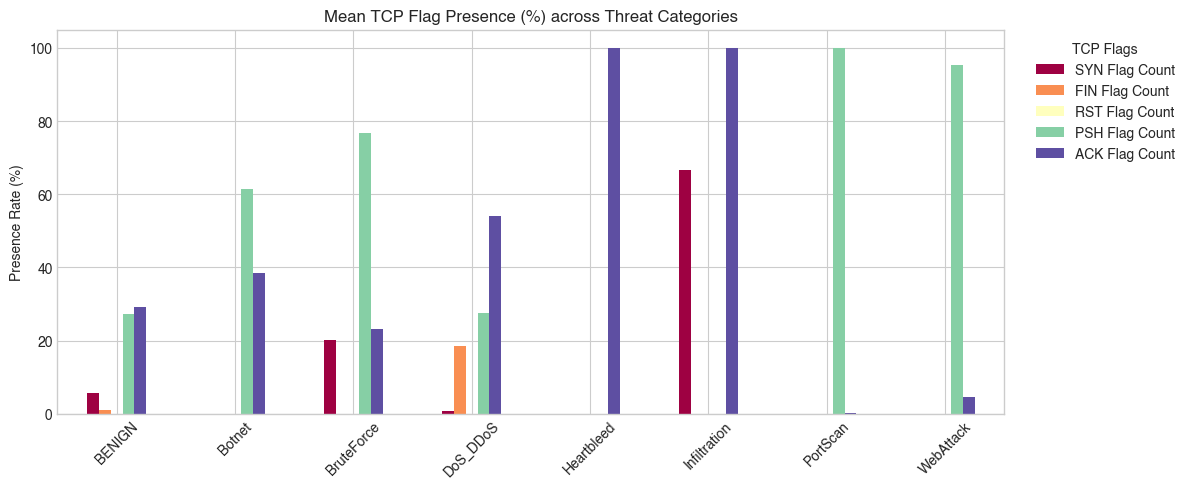

In [8]:
# TCP Control Flags across categories
flag_cols = ['SYN Flag Count', 'FIN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count']
flag_means = df_dev.groupby('label_category')[flag_cols].mean() * 100

fig, ax = plt.subplots(figsize=(12, 5))
flag_means.plot(kind='bar', ax=ax, colormap='Spectral')
ax.set_title("Mean TCP Flag Presence (%) across Threat Categories", fontsize=12, fontweight='bold')
ax.set_ylabel("Presence Rate (%)")
ax.set_xlabel("")
ax.tick_params(axis='x', rotation=45)
ax.legend(title="TCP Flags", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()


## 6. Feature Correlation & Multicollinearity
Examine feature-to-feature and feature-to-target correlations using Spearman rank correlation.


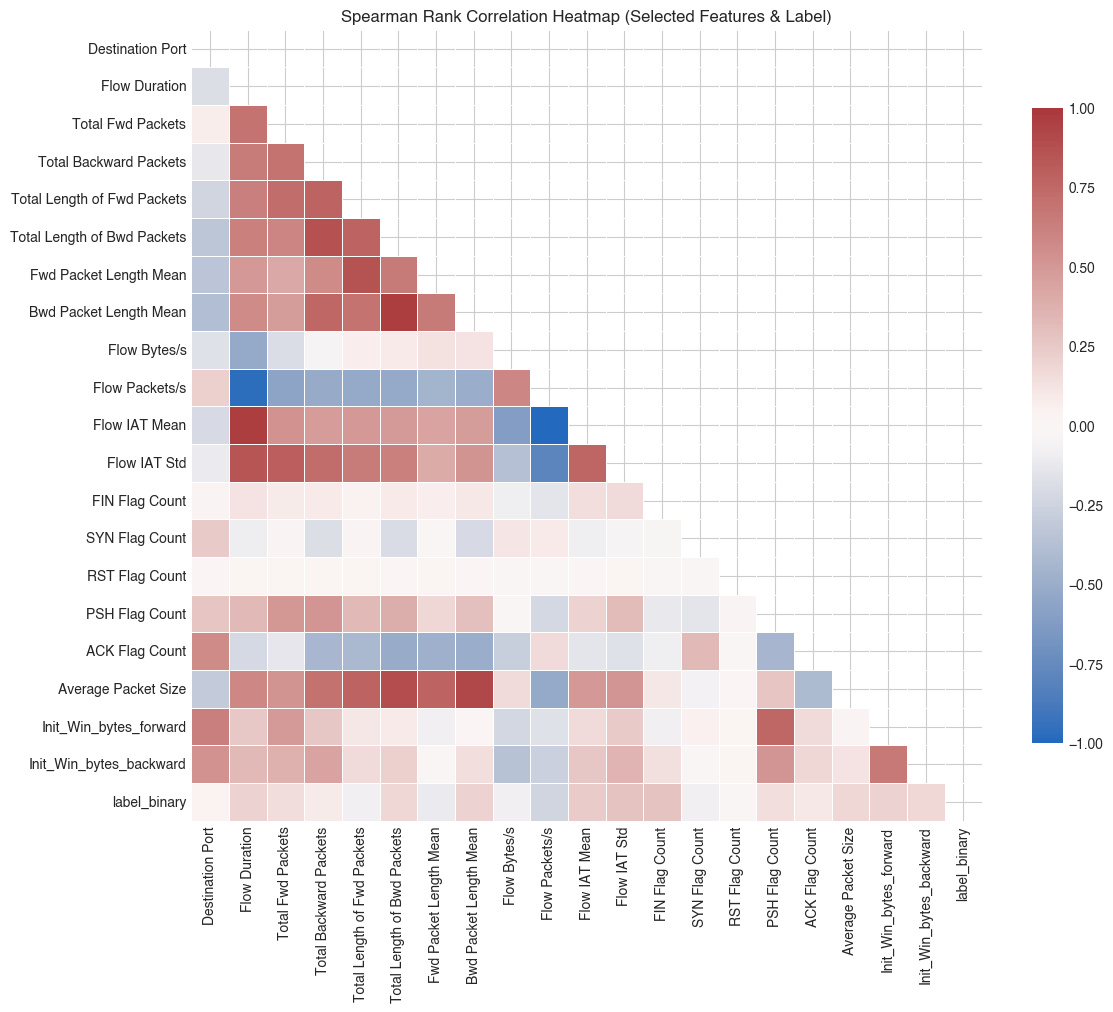

In [9]:
corr_features = [
    'Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
    'Total Length of Fwd Packets', 'Total Length of Bwd Packets',
    'Fwd Packet Length Mean', 'Bwd Packet Length Mean',
    'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std',
    'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count',
    'Average Packet Size', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward',
    'label_binary'
]

corr_matrix = df_dev[corr_features].corr(method='spearman')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, mask=mask, cmap='vlag', vmin=-1, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Spearman Rank Correlation Heatmap (Selected Features & Label)", fontsize=12, fontweight='bold')
plt.tight_layout()


## 7. Threat Family Statistical Profile
Summary metrics across all threat families:


In [10]:
summary = df_dev.groupby('label_category').agg({
    'Flow Duration': 'median',
    'Flow Bytes/s': 'median',
    'Flow Packets/s': 'median',
    'Total Fwd Packets': 'median',
    'Total Backward Packets': 'median',
    'Average Packet Size': 'mean',
    'PSH Flag Count': lambda x: (x > 0).mean() * 100,
    'ACK Flag Count': lambda x: (x > 0).mean() * 100,
    'label_binary': 'count'
}).rename(columns={'label_binary': 'Sample_Count'})

summary.columns = [
    'Median Duration (µs)', 'Median Bytes/s', 'Median Pkts/s',
    'Median Fwd Pkts', 'Median Bwd Pkts', 'Mean Avg Pkt Size (B)',
    'PSH Flag %', 'ACK Flag %', 'Sample Count'
]
print(summary.to_string())


                Median Duration (µs)  Median Bytes/s  Median Pkts/s  Median Fwd Pkts  Median Bwd Pkts  Mean Avg Pkt Size (B)  PSH Flag %  ACK Flag %  Sample Count
label_category                                                                                                                                                    
BENIGN                       46278.0     4111.600586      84.545151              2.0              2.0             132.142700   27.278316   29.141831        165923
Botnet                       68786.5     5224.191895     104.884277              3.0              3.0              64.392601   61.538462   38.461538           156
BruteForce                 9233919.5      365.609009       4.158863              9.0             15.0              39.839485   76.775956   23.224044           732
DoS_DDoS                  72018736.0      138.228836       0.179821              5.0              5.0             805.902954   27.460576   54.128797         25746
Heartbleed            

## 8. Key Takeaways for Machine Learning Engine (Phase 4)
1. **Port Specialization**: `Destination Port` separates targeted brute-force (Ports 21/22) and web attacks (Port 80) from reconnaissance and benign activity.
2. **Rate & Duration Signatures**: Volumetric DoS/DDoS flows demonstrate long median durations ($>7.2	imes 10^7\,\mu	ext{s}$) with large packet payloads ($>800$ Bytes). Conversely, PortScan flows have ultra-short durations ($50\,\mu	ext{s}$) with single packets.
3. **TCP Flag Signals**: `PSH Flag Count` is active in over 99.9% of PortScan flows and 95.3% of WebAttacks, but only 27% of Benign traffic.
4. **Multicollinearity Caution**: Features like `Total Length of Fwd Packets` and `Subflow Fwd Bytes` have near 1.0 correlation and can be pruned or handled via tree models.
5. **Rare Class Strategy**: Heartbleed (11 flows) and Infiltration (36 flows) require macro-averaging and cost-sensitive evaluation or grouping to avoid being drowned out.
